<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_05_Classification/Chapter_05_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 5 — Classification

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced and executed, and a short analysis of the outputs |

## Chapter overview

Classification predicts a **category** (default or paid off, spam or not) instead of a number. Most methods of the chapter do not only output a class but a **probability** of each class, and the class is chosen by comparing the probability with a cutoff. The chapter presents three models of increasing use in practice: **naive Bayes**, **discriminant analysis** and **logistic regression**, the last one being the workhorse. It then turns to how a classifier is **evaluated** (confusion matrix, precision, recall, specificity, ROC curve, AUC, lift), which is not trivial when one class is rare, and to **strategies for imbalanced data** (undersampling, oversampling, weighting, synthetic data, cost-based classification). It closes by comparing what different classifiers predict for the same data.

### Sections of this chapter

| # | Section of the book | Python code in the book |
|---|---|---|
| 1 | Naive Bayes | the naive solution for loan data with categorical predictors |
| 2 | Discriminant analysis | linear discriminant analysis of loans and its decision boundary |
| 3 | Logistic regression | the logit, scikit-learn and `statsmodels` fits, odds, a spline model, a partial residual plot |
| 4 | Evaluating classification models | confusion matrix, precision, recall, specificity, ROC curve, AUC |
| 5 | Strategies for imbalanced data | undersampling, weighting, SMOTE and ADASYN, a comparison of four classifiers |

### How to read this notebook

Every section has the same structure: a **Summary** (what the book says, condensed in my own words; the book itself is not quoted), the **Theory** behind the section, the **Book code** (the official Python code of the chapter, reproduced and executed) and a short **Output analysis**.

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository (the setup cells are labelled `# SETUP` and are not part of the book). The book's code is reproduced as it is; where it needs a change to run on current library versions, the change is marked in the cell with `# CHANGED` and explained in the text.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). The files of this chapter are `loan_data.csv.gz` (45,342 loans, half of them in default), `loan3000.csv` (a sample of 3,000 loans) and `full_train_set.csv.gz` (119,987 loans, of which about 19% are in default).

The setup cell also prints the versions of the libraries, because the code of the book was written for older ones. Three libraries that the chapter needs are not part of a standard Python installation: `imbalanced-learn` (SMOTE and ADASYN), `pygam` (a generalized additive model) and `dmba` (the confusion matrix summary of the book's authors); the cell installs them if they are missing (this is the case in Google Colab).

In [1]:
# SETUP
import importlib.util
import platform
import subprocess
import sys
import urllib.request
import warnings
from pathlib import Path

# Google Colab does not ship these libraries; install them when they are missing
for module, package in (("imblearn", "imbalanced-learn"), ("pygam", "pygam"), ("dmba", "dmba")):
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import imblearn
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pygam
import scipy
import seaborn as sns
import sklearn
import statsmodels

print(f"Python           : {platform.python_version()}")
print(f"NumPy            : {np.__version__}")
print(f"pandas           : {pd.__version__}")
print(f"SciPy            : {scipy.__version__}")
print(f"statsmodels      : {statsmodels.__version__}")
print(f"scikit-learn     : {sklearn.__version__}")
print(f"imbalanced-learn : {imblearn.__version__}")
print(f"pygam            : {pygam.__version__}")
print(f"seaborn          : {sns.__version__}")
print(f"Matplotlib       : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"
# the book's code passes penalty='l2' to LogisticRegression, which scikit-learn 1.8 and later deprecates (see the book-vs-library notes);
# the warning would be repeated for every fit below, so it is silenced here
warnings.filterwarnings("ignore", message="'penalty' was deprecated", category=FutureWarning)

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("loan3000.csv", "loan_data.csv.gz", "full_train_set.csv.gz")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) --------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE + ["#8e5ea2", "#6b6a63"]),  # two more colours for plots with four or five lines
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python           : 3.12.3
NumPy            : 2.5.4
pandas           : 3.1.0
SciPy            : 1.16.3
statsmodels      : 0.15.0
scikit-learn     : 1.9.1
imbalanced-learn : 0.14.2
pygam            : 0.12.0
seaborn          : 0.13.2
Matplotlib       : 3.11.2


The imports and the paths of the official script follow (the official script finds its data folder with a helper module; here `DATA` comes from the setup cell). The script ends its imports with an empty `print()`, which only separates the messages of the imported packages from the output of the code. Importing `dmba` has a side effect: when it finds no display (a server, or a notebook run in the background) it prints a message and switches Matplotlib to the non-interactive `Agg` backend, and then no figure appears in the notebook. The cell after the imports, which is not part of the book, switches the figures on again.

In [2]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression #, LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.metrics import roc_curve, accuracy_score, roc_auc_score

import statsmodels.api as sm

from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE
from pygam import LinearGAM, s, f, l


from dmba import classificationSummary

import seaborn as sns
import matplotlib.pyplot as plt
print()

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
FULL_TRAIN_SET_CSV = DATA / 'full_train_set.csv.gz'

no display found. Using non-interactive Agg backend



In [3]:
# SETUP (continued; not in the book): show the figures in the notebook although `dmba` may have selected the Agg backend
%matplotlib inline

---
## 1. Naive Bayes

*Book section: "Naive Bayes" (why exact Bayesian classification is impractical, the naive solution, numeric predictor variables). The code of the script classifies a loan from its purpose, the home ownership and the length of employment.*

### Summary

* The **naive Bayes** algorithm classifies a record by the probability of each class given the observed values of the predictors. For a record with predictor values $x_1, \dots, x_p$ it asks: among the records with exactly these values, which share belongs to each class? This is the **exact Bayesian classification**.
* The exact approach is **impractical**: with many predictors there are few or no records that match a given combination of values exactly (and none at all for new combinations), so the probabilities cannot be estimated.
* The **naive solution** replaces the exact probability by the product of the probabilities of each predictor value in each class, as if the predictors were independent given the class (that is the "naive" part). The class probabilities are then rescaled to add up to one. Despite the unrealistic assumption, the method often classifies well, because only the ranking of the class probabilities has to be right.
* **Numeric predictors** have to be handled: either converted to categories (binning) and treated like a factor, or modelled with a probability density (for example a normal distribution within each class). The book illustrates this with R code that has no Python counterpart in the script (it is commented out); scikit-learn's `MultinomialNB` works for counts and indicator variables only.
* The example of the script: for one loan the naive Bayes model predicts the class *default* with a probability of 0.654 (and 0.346 for *paid off*).

### Theory

**Bayes' rule.** For classes $c \in \{1, \dots, K\}$ and a record $x$,
$$P(Y = c \mid x) = \frac{P(x \mid Y = c)\,P(Y = c)}{\sum_{k} P(x \mid Y = k)\,P(Y = k)} .$$
The exact approach estimates $P(x \mid Y = c)$ from the matching records; for $p$ predictors with several levels each there are exponentially many combinations.

**The naive assumption.** If the predictors are independent given the class, $P(x \mid Y = c) = \prod_{j=1}^p P(x_j \mid Y = c)$, and every factor is estimated from a one-dimensional table. The predicted class is $\arg\max_c P(Y = c)\prod_j P(x_j \mid Y = c)$; the product is usually computed as a sum of logarithms to avoid very small numbers.

**Smoothing.** A value that never occurs together with a class in the training data would make the whole product zero. The parameter `alpha` of `MultinomialNB` adds a pseudo-count to every cell of the tables (Laplace smoothing for $\alpha = 1$). The script's second model uses `alpha=1e-10`, practically no smoothing, and `fit_prior=False`, which makes the two classes equally likely a priori (the loan data are balanced anyway).

**Why it works despite the assumption.** The predictors are usually correlated, so the probabilities of the model are not exact (they tend to be too extreme). The classification only needs the class with the largest probability, which is often still the right one.

### Book code

The script reads the loan data and converts the outcome and the three predictors to categorical variables. (The call `reorder_categories` is not assigned to anything and has no effect.) The predictors are then coded as indicator columns and the model is fitted; the script defines the model twice, and the second definition (almost no smoothing, equal prior probabilities) replaces the first one.

In [4]:
# BOOK CODE (Naive Bayes, The Naive Solution): the loan data and the model
loan_data = pd.read_csv(LOAN_DATA_CSV)

# convert to categorical
loan_data.outcome = loan_data.outcome.astype('category')
loan_data.outcome.cat.reorder_categories(['paid off', 'default'])
loan_data.purpose_ = loan_data.purpose_.astype('category')
loan_data.home_ = loan_data.home_.astype('category')
loan_data.emp_len_ = loan_data.emp_len_.astype('category')

predictors = ['purpose_', 'home_', 'emp_len_']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='', dtype=int)
y = loan_data[outcome]

naive_model = MultinomialNB(alpha=0.01, fit_prior=True)
naive_model = MultinomialNB(alpha=1e-10, fit_prior=False)
naive_model.fit(X, y)

MultinomialNB(alpha=1e-10, fit_prior=False)

The prediction for one loan, the one in row 146.

In [5]:
# BOOK CODE (Naive Bayes, The Naive Solution): the prediction for a new loan
new_loan = X.loc[146:146, :]
print('predicted class: ', naive_model.predict(new_loan)[0])

probabilities = pd.DataFrame(naive_model.predict_proba(new_loan),
                             columns=naive_model.classes_)
print('predicted probabilities',)
print(probabilities)

predicted class:  default
predicted probabilities
    default  paid off
0  0.653699  0.346301


**Output analysis.**

* **The model.** The cell shows the fitted estimator, `MultinomialNB(alpha=1e-10, fit_prior=False)`: practically no smoothing and equal prior probabilities for the two classes.
* **The prediction.** For the loan in row 146 the model predicts *default*, with a probability of 0.654 for default and 0.346 for paid off. As the two classes are equally frequent in these data, the prior probability of default is 0.5, so the purpose, the home ownership and the length of employment of this loan raise the probability of default to about 0.65 according to the model.
* The probabilities of a naive Bayes model multiply the evidence of the predictors as if they were independent; when the predictors are correlated they can be overconfident, and the classification (the larger of the two probabilities) is the part to rely on.

---
## 2. Discriminant analysis

*Book section: "Discriminant Analysis" (the covariance matrix, Fisher's linear discriminant, a simple example). The code of the script fits a linear discriminant to the borrower score and the payment-to-income ratio of 3,000 loans.*

### Summary

* **Discriminant analysis** is the oldest classification method (Fisher, 1936). It is used for numeric predictors and finds a function of them that **best separates the classes**. Today it is less used than logistic regression and the tree methods, but it is still useful and closely related to them.
* The **covariance matrix** describes the variances of the predictors and their covariances (how they move together). Discriminant analysis uses the covariance matrix *within* the classes, pooled over the classes, which assumes that it is the same in all classes.
* **Fisher's linear discriminant** looks for the linear combination of the predictors that maximizes the ratio of the variation *between* the classes to the variation *within* them. The coefficients of this combination are the **scalings** (the discriminant weights). A record's value of the combination, the **discriminant score**, is turned into a class probability.
* The example of the script: with the borrower score and the payment-to-income ratio of 3,000 loans, the discriminant weights are 7.18 for the borrower score and -0.10 for the payment-to-income ratio, and the figure shows the straight line that divides the plane into the region of predicted *default* and that of predicted *paid off*; the line passes through the midpoint of the two class means.
* The assumptions (normal predictors with the same covariance matrix in all classes) are rarely true, but the method is fairly robust to deviations and is often good for classification.

### Theory

**The model.** Suppose that in class $k$ the predictors are multivariate normal with mean $\mu_k$ and a common covariance matrix $\Sigma$. By Bayes' rule, the log of the ratio of the probabilities of the classes 1 and 2 is linear in $x$:
$$\ln\frac{P(Y=1\mid x)}{P(Y=2\mid x)} = (\mu_1 - \mu_2)^\top\Sigma^{-1}x - \tfrac12(\mu_1 + \mu_2)^\top\Sigma^{-1}(\mu_1 - \mu_2) + \ln\frac{\pi_1}{\pi_2},$$
where $\pi_k$ are the prior probabilities. The classes are separated by the hyperplane where this expression is zero, so the decision boundary is a straight line (hence *linear* discriminant analysis).

**Fisher's criterion.** For a direction $w$ the ratio $\dfrac{w^\top S_B w}{w^\top S_W w}$ of the between-class and the within-class scatter is largest for $w \propto S_W^{-1}(\bar x_1 - \bar x_2)$, the same direction as above with the sample estimates of $\mu_k$ and $\Sigma$. For two classes the discriminant score is therefore a single number per record.

**Relation to logistic regression.** Both models have a linear log-odds. Discriminant analysis estimates it through the means and the covariance of the predictors (and relies on normality), logistic regression estimates the coefficients of the log-odds directly by maximum likelihood and makes no assumption on the distribution of the predictors, which makes it more robust.

### Book code

The script reads the 3,000 loans and fits the discriminant analysis with the borrower score and the payment-to-income ratio. The scalings are the discriminant weights; `predict_proba` gives the probability of each class for each loan.

In [6]:
# BOOK CODE (Discriminant Analysis, A Simple Example): linear discriminant analysis
loan3000 = pd.read_csv(LOAN3000_CSV)
loan3000.outcome = loan3000.outcome.astype('category')

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)
print(pd.DataFrame(loan_lda.scalings_, index=X.columns))

pred = pd.DataFrame(loan_lda.predict_proba(loan3000[predictors]),
                    columns=loan_lda.classes_)
print(pred.head())

                          0
borrower_score     7.178232
payment_inc_ratio -0.099709
    default  paid off
0  0.553591  0.446409
1  0.559004  0.440996
2  0.272576  0.727424
3  0.506270  0.493730
4  0.610035  0.389965


Figure 5.1 of the book: the loans coloured by their predicted probability of default, with the line that separates the two predicted classes (it is computed from the scalings and the center of the class means) and the two class means.

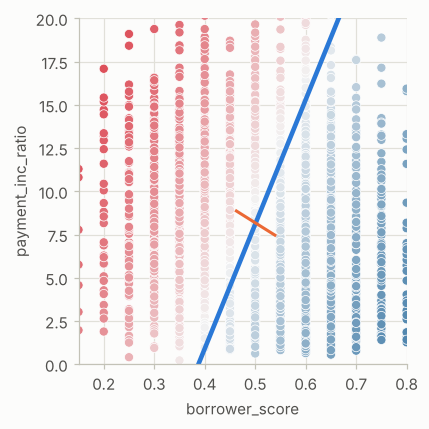

In [7]:
# BOOK CODE (Discriminant Analysis): the decision line
# Use scalings and center of means to determine decision boundary
center = np.mean(loan_lda.means_, axis=0)
slope = - loan_lda.scalings_[0] / loan_lda.scalings_[1]
intercept = center[1] - center[0] * slope

# payment_inc_ratio for borrower_score of 0 and 20
x_0 = (0 - intercept) / slope
x_20 = (20 - intercept) / slope

lda_df = pd.concat([loan3000, pred['default']], axis=1)
lda_df.head()

fig, ax = plt.subplots(figsize=(4, 4))
g = sns.scatterplot(x='borrower_score', y='payment_inc_ratio',
                    hue='default', data=lda_df,
                    palette=sns.diverging_palette(240, 10, n=9, as_cmap=True),
                    ax=ax, legend=False)

ax.set_ylim(0, 20)
ax.set_xlim(0.15, 0.8)
ax.plot((x_0, x_20), (0, 20), linewidth=3)
ax.plot(*loan_lda.means_.transpose())

plt.tight_layout()
plt.show()

**Output analysis.**

* **The scalings** (the discriminant weights) are 7.178 for the borrower score and -0.0997 for the payment-to-income ratio. The predictors are on different scales (the score from about 0.15 to 0.8, the ratio from 0 to 20), so the weights cannot be compared directly: over the ranges shown in the figure, the borrower score contributes about $7.18 \times 0.65 \approx 4.7$ units to the discriminant score and the ratio about $0.0997 \times 20 \approx 2.0$.
* **The predicted probabilities** of the first five loans are 0.554, 0.559, 0.273, 0.506 and 0.610 for default, so the first, second, fourth and fifth are predicted as defaults, narrowly for the fourth.
* **The figure.** The loans with a low borrower score are red (a high probability of default) and those with a high score are blue. The straight line is the boundary where the two classes are equally probable; it runs from a borrower score of about 0.39 at a payment-to-income ratio of 0 to about 0.66 at a ratio of 20: the larger the payment burden, the higher the borrower score that is needed to be predicted as paid off. The orange segment connects the means of the two classes; the line passes through its midpoint.

---
## 3. Logistic regression

*Book section: "Logistic Regression" (logistic response function and logit, logistic regression and the GLM, generalized linear models, predicted values, interpreting the coefficients and odds ratios, linear and logistic regression: similarities and differences, assessing the model). The code of the script predicts the default of loans from the payment-to-income ratio, the borrower score, the purpose, the home ownership and the length of employment.*

### Summary

* **Logistic regression** is like multiple linear regression, except that the outcome is binary (a 0/1 variable such as default). It is the most widely used classification method in practice, because it is fast, produces a model that is easy to interpret, and can be updated easily.
* The linear model cannot be used directly, since a linear function is not limited to the range of a probability. Logistic regression transforms the probability with the **logit** (the logarithm of the **odds**), $\operatorname{logit}(p) = \ln\frac{p}{1-p}$, which can take any real value, and models the logit as a linear function of the predictors. The inverse transformation, the **logistic response function**, turns the linear function back into a probability between 0 and 1.
* The **odds** of an event are the ratio of the probability that it occurs to the probability that it does not: odds of 3 mean a probability of 0.75. An **odds ratio** compares the odds for two values of a predictor. A coefficient of the model is the **change of the log-odds** per unit of the predictor, and its exponential is the odds ratio.
* Logistic regression is a special case of the **generalized linear model (GLM)**: a model with a response distribution (here the binomial) and a link function (here the logit) that connects the mean of the response to the linear predictor. It is fitted by **maximum likelihood** with an iterative algorithm (iteratively reweighted least squares), not by a closed-form solution. In Python it is available in scikit-learn (class `LogisticRegression`, designed for prediction) and in `statsmodels` (`GLM` with the binomial family, which gives the statistical output of a regression).
* **Predicted values** can be given as the log-odds, as the odds or as the probability; the probability is compared with a cutoff to obtain the class. The model of the script predicts default with probabilities that range from about 0.06 to 0.97.
* **Assessing the model** can be done as for multiple regression: the coefficients with their standard errors and p-values, the residuals, and diagnostics such as the partial residual plot, which exists also for logistic regression. The model is assessed on its classification performance as well (section 4). Nonlinear terms such as splines can be added to the linear predictor, as in the second model of the script.

### Theory

**The model.** With $p = P(Y = 1 \mid x)$,
$$\ln\frac{p}{1-p} = \beta_0 + \beta_1x_1 + \dots + \beta_px_p, \qquad p = \frac{1}{1 + e^{-(\beta_0 + \beta_1x_1 + \dots + \beta_px_p)}} .$$
A one-unit increase of $x_j$, the others held fixed, multiplies the odds by $e^{\beta_j}$. For small probabilities the odds ratio is close to the ratio of the probabilities (the relative risk).

**Maximum likelihood.** Given the data $(x_i, y_i)$ with $y_i \in \{0, 1\}$, the coefficients maximize the log-likelihood $\ell(\beta) = \sum_i \bigl[y_i\ln p_i + (1 - y_i)\ln(1 - p_i)\bigr]$. The gradient is $X^\top(y - p)$; the solution has no closed form and is found by Newton's method, which is a sequence of weighted least squares fits (iteratively reweighted least squares) with weights $p_i(1 - p_i)$. The covariance matrix of the estimates is $(X^\top W X)^{-1}$ at the solution, which gives the standard errors and the $z$ statistics.

**Deviance.** The deviance $D = -2\ell(\hat\beta)$ (for 0/1 data) plays the role of the residual sum of squares: a smaller value means a better fit. The difference of the deviances of two nested models is, under the smaller model, approximately chi-square distributed.

**Regularization in scikit-learn.** `LogisticRegression` minimizes the negative log-likelihood plus a penalty with the strength $1/C$. The script sets `penalty='l2'` and `C=1e42`, which makes the penalty negligible and the fit practically the same as the unpenalized maximum likelihood fit of `statsmodels`.

**The coding of the classes.** A binary classifier needs one class as the "positive" one. scikit-learn orders the classes (here alphabetically: `default`, `paid off`) and its coefficients describe the log-odds of the *second* class, `paid off`; `statsmodels` models the class coded 1. The script's coefficients therefore have the opposite sign to those of a model of default (the script's note compares with the R model of the book).

### Book code

The logit as a function of the probability: it is 0 at $p = 0.5$ and tends to $\pm\infty$ at 0 and 1.

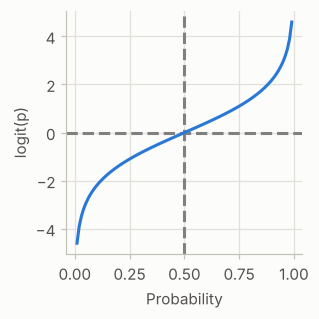

In [8]:
# BOOK CODE (Logistic Response Function and Logit): the logit
p = np.arange(0.01, 1, 0.01)
df = pd.DataFrame({
    'p': p,
    'logit': np.log(p / (1 - p)),
    'odds': p / (1 - p),
})

fig, ax = plt.subplots(figsize=(3, 3))
ax.axhline(0, color='grey', linestyle='--')
ax.axvline(0.5, color='grey', linestyle='--')
ax.plot(df['p'], df['logit'])
ax.set_xlabel('Probability')
ax.set_ylabel('logit(p)')

plt.tight_layout()
plt.show()

The logistic regression with scikit-learn. The categorical predictors are coded with dummy variables (one level of each is dropped, as a reference), the penalty is made negligible with `C=1e42`, and the intercept and the coefficients are printed.

In [9]:
# BOOK CODE (Logistic Regression and the GLM): the fit with scikit-learn
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'borrower_score']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = loan_data[outcome] # .cat.categories

logit_reg = LogisticRegression(penalty='l2', C=1e42, solver='liblinear')
logit_reg.fit(X, y)

print('intercept ', logit_reg.intercept_[0])
print('classes', logit_reg.classes_)
pd.DataFrame({'coeff': logit_reg.coef_[0]},
             index=X.columns)

intercept  -1.638088482278965
classes ['default' 'paid off']


,coeff
payment_inc_ratio,-0.079728
borrower_score,4.611037
debt_consolidation,-0.249342
home_improvement,-0.407614
major_purchase,-0.229375
medical,-0.510087
other,-0.620534
small_business,-1.215662
OWN,-0.048453
RENT,-0.157355


The script notes that the intercept and the coefficients are reversed compared with the R model of the book, and prints the reference levels of the three factors (the first level of each, which `drop_first=True` leaves out).

In [10]:
# BOOK CODE (Logistic Regression and the GLM): the categories of the factors
# Note that the intercept and coefficients are reversed compared to the R model.

print(loan_data['purpose_'].cat.categories)
print(loan_data['home_'].cat.categories)
print(loan_data['emp_len_'].cat.categories)

Index(['credit_card', 'debt_consolidation', 'home_improvement', 'major_purchase', 'medical', 'other', 'small_business'], dtype='str')
Index(['MORTGAGE', 'OWN', 'RENT'], dtype='str')
Index([' < 1 Year', ' > 1 Year'], dtype='str')


Not in the book (a note of the official script): coding the outcome as numbers with an `OrdinalEncoder`, with `paid off` as 0 and `default` as 1, reverses the order of the classes and, as a consequence, the signs of the coefficients.

In [11]:
# BOOK CODE (Not in book): the outcome coded as 0 (paid off) and 1 (default)
# _Not in book_ :
# If you have a feature or outcome variable that is ordinal, use the scikit-learn `OrdinalEncoder` to replace the categories (here, 'paid off' and 'default') with numbers. In the below code, we replace 'paid off' with 0 and 'default' with 1. This reverses the order of the predicted classes and as a consequence, the coefficients will be reversed.

from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder(categories=[['paid off', 'default']])
y_enc = enc.fit_transform(loan_data[[outcome]]).ravel()

logit_reg_enc = LogisticRegression(penalty="l2", C=1e42, solver='liblinear')
logit_reg_enc.fit(X, y_enc)

print('intercept ', logit_reg_enc.intercept_[0])
print('classes', logit_reg_enc.classes_)
pd.DataFrame({'coeff': logit_reg_enc.coef_[0]},
             index=X.columns)

intercept  1.6378909053062045
classes [0. 1.]


,coeff
payment_inc_ratio,0.079739
borrower_score,-4.612183
debt_consolidation,0.249414
home_improvement,0.407734
major_purchase,0.229710
medical,0.510744
other,0.620800
small_business,1.214936
OWN,0.048211
RENT,0.157288


Predicted values: the distribution of the predicted log-probabilities and of the predicted probabilities of the two classes.

In [12]:
# BOOK CODE (Predicted Values from Logistic Regression): predicted log-probabilities and probabilities
pred = pd.DataFrame(logit_reg.predict_log_proba(X),
                    columns=logit_reg.classes_)
print(pred.describe())

pred = pd.DataFrame(logit_reg.predict_proba(X),
                    columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean      -0.757850     -0.760423
std        0.378032      0.390419
min       -2.768873     -3.538864
25%       -0.985728     -0.977164
50%       -0.697366     -0.688946
75%       -0.472209     -0.467076
max       -0.029476     -0.064787
            default      paid off
count  45342.000000  45342.000000
mean       0.500001      0.499999
std        0.167336      0.167336
min        0.062733      0.029046
25%        0.373167      0.376377
50%        0.497895      0.502105
75%        0.623623      0.626833
max        0.970954      0.937267


The relation between the odds and the log-odds (the inverse of the logit).

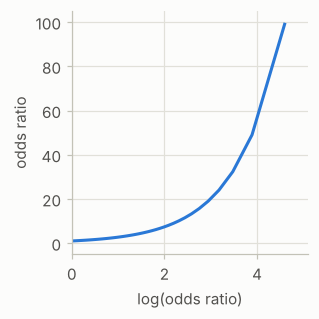

In [13]:
# BOOK CODE (Interpreting the Coefficients and Odds Ratios): odds against log-odds
fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(df['logit'], df['odds'])
ax.set_xlabel('log(odds ratio)')
ax.set_ylabel('odds ratio')
ax.set_xlim(0, 5.1)
ax.set_ylim(-5, 105)

plt.tight_layout()
plt.show()

Assessing the model. The same model with `statsmodels` and its GLM with the binomial family; this method requires the outcome as numbers (1 for default), and the summary gives the standard errors, $z$ statistics and p-values.

In [14]:
# BOOK CODE (Assessing the Model): the GLM of statsmodels
# use GLM (general linear model) with the binomial family to
# fit a logistic regression
y_numbers = [1 if yi == 'default' else 0 for yi in y]
logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
print(logit_result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Sat, 24 Oct 2026   Deviance:                       57515.
Time:                        16:51:40   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0

A model with splines (`bs`) for the payment-to-income ratio and the borrower score, fitted with a formula.

In [15]:
# BOOK CODE (Assessing the Model): a model with splines
# Use splines

import statsmodels.formula.api as smf
formula = ('outcome ~ bs(payment_inc_ratio, df=8) + purpose_ + ' +
           'home_ + emp_len_ + bs(borrower_score, df=3)')
model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()
print(results.summary())

                             Generalized Linear Model Regression Results                             
Dep. Variable:     ['outcome[default]', 'outcome[paid off]']   No. Observations:                45342
Model:                                                   GLM   Df Residuals:                    45321
Model Family:                                       Binomial   Df Model:                           20
Link Function:                                         Logit   Scale:                          1.0000
Method:                                                 IRLS   Log-Likelihood:                -28731.
Date:                                       Sat, 24 Oct 2026   Deviance:                       57462.
Time:                                               16:51:40   Pearson chi2:                 4.54e+04
No. Iterations:                                            6   Pseudo R-squ. (CS):             0.1122
Covariance Type:                                   nonrobust                      

The function `partialResidualPlot` of the script computes the partial residuals of one predictor in a logistic regression; the plot shows the relationship of the payment-to-income ratio with the log-odds, after taking out the other predictors.

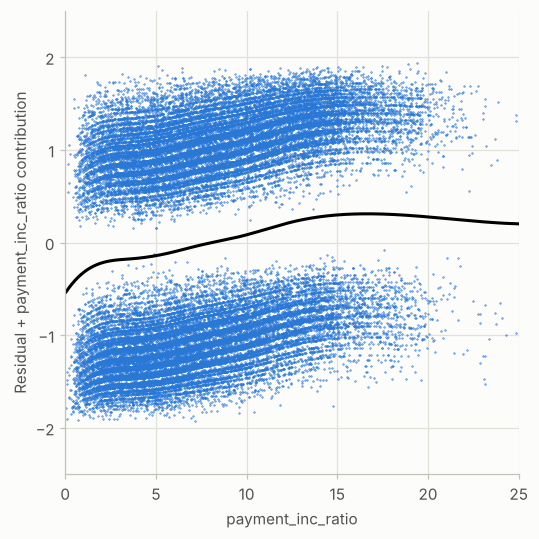

In [16]:
# BOOK CODE (Assessing the Model): the partial residual plot of the spline model
from statsmodels.genmod.generalized_linear_model import GLMResults
def partialResidualPlot(model, df, outcome, feature, fig, ax):
    y_actual = [0 if s == 'default' else 1 for s in df[outcome]]
    y_pred = model.predict(df)
    org_params = model.params.copy()
    zero_params = model.params.copy()
    # set model parameters of other features to 0
    for i, name in enumerate(zero_params.index):
        if feature in name:
            continue
        zero_params.iloc[i] = 0.0
    model.initialize(model.model, zero_params)
    feature_prediction = model.predict(df)
    ypartial = -np.log(1/feature_prediction - 1)
    ypartial = ypartial - np.mean(ypartial)
    model.initialize(model.model, org_params)
    results = pd.DataFrame({
        'feature': df[feature],
        'residual': -2 * (y_actual - y_pred),
        'ypartial': ypartial/ 2,
    })
    results = results.sort_values(by=['feature'])

    ax.scatter(results.feature, results.residual, marker=".", s=72./fig.dpi)
    ax.plot(results.feature, results.ypartial, color='black')
    ax.set_xlabel(feature)
    ax.set_ylabel(f'Residual + {feature} contribution')
    return ax

fig, ax = plt.subplots(figsize=(5, 5))
partialResidualPlot(results, loan_data, 'outcome', 'payment_inc_ratio', fig, ax)
ax.set_xlim(0, 25)
ax.set_ylim(-2.5, 2.5)


plt.tight_layout()
plt.show()

**Output analysis.**

* **The logit** is zero at a probability of 0.5, negative below and positive above it, and it grows without bound towards 0 and 1 (about -4.6 at 0.01 and +4.6 at 0.99). The odds against the log-odds (the last figure of the section) is the exponential curve: a log-odds of 4.6 is odds of 100.
* **The coefficients of scikit-learn.** The classes are `default` and `paid off`, in this order, so the coefficients describe the log-odds of the *second* class, `paid off`: a higher borrower score raises it (+4.611) and a higher payment-to-income ratio lowers it (-0.0797); the other purposes have negative coefficients relative to the reference `credit_card` (largest for a small business, -1.216), `RENT` relative to `MORTGAGE` is negative (-0.157), and a length of employment of more than a year is positive (+0.357). With the coding `paid off` = 0 and `default` = 1 (the `OrdinalEncoder` example of the script) the intercept changes from -1.638 to +1.638 and every coefficient changes sign, giving the coefficients of default.
* **Reading them as odds ratios** (from the `statsmodels` coefficients of default): a small-business loan has $e^{1.2153} \approx 3.4$ times the odds of default of a credit-card loan with the same other characteristics, a renter $e^{0.157} \approx 1.17$ times those of a borrower with a mortgage, and a longer employment $e^{-0.357} \approx 0.70$ times (30% lower). Owning the home does not differ clearly from having a mortgage ($p = 0.204$). The reference levels printed are `credit_card`, `MORTGAGE` and ` < 1 Year`.
* **Predicted values.** The predicted probability of default has an average of 0.5 (the same as the share of defaults in these data), ranges from 0.063 to 0.971 and has a standard deviation of 0.167; the middle half of the loans has probabilities between 0.373 and 0.624, so the model separates the loans only moderately.
* **The `statsmodels` summary** has the same coefficients as scikit-learn with the opposite sign (the small differences in the third or fourth significant digit come from the different algorithms), with standard errors and $z$ statistics: the largest are for the borrower score ($z = -55.2$) and the payment-to-income ratio ($z = 32.1$). The deviance is 57,515 and the pseudo R-squared 0.111.
* **The spline model** has a deviance of 57,462, 53 lower than the linear one with 9 more coefficients: a statistically clear but small improvement (pseudo R-squared 0.1122 against 0.1112). The last spline coefficients have very large standard errors and have no individual meaning.
* **The partial residual plot.** The points form two bands (the two outcomes). The black line, the contribution of the payment-to-income ratio to the log-odds, rises from about -0.5 at a ratio of 0 to about 0.3 at a ratio of 15 and is flat or slightly lower beyond it: the effect is not a straight line, which a linear term (0.08 per unit) would overstate for large ratios.

---
## 4. Evaluating classification models

*Book section: "Evaluating Classification Models" (confusion matrix, the rare class problem, precision, recall and specificity, ROC curve, AUC, lift). The code of the script evaluates the logistic regression of section 3.*

### Summary

* **Accuracy**, the share of correct classifications, is the simplest measure of a classifier, but it can be misleading. A model for a rare class (fraud, a disease, a default among mostly good loans) can have a high accuracy by always predicting the common class and still be useless.
* The **confusion matrix** counts the records by true class and predicted class: **true positives** (a positive record predicted positive), **false negatives**, **false positives** and **true negatives**. All the other measures are computed from it.
* **Precision** is the share of the records predicted positive that are positive; **recall** (or **sensitivity**) is the share of the positive records that are found; **specificity** is the share of the negative records that are correctly identified as negative. There is a trade-off between them, set by the cutoff for the predicted probability.
* The **rare class problem**: when one class is rare, accuracy is dominated by the common class, and the measures of the rare class (precision and recall) are the relevant ones; section 5 takes up the methods to improve the classification of a rare class.
* The **ROC curve** (receiver operating characteristic) plots the recall against the specificity (or the false positive rate) for all possible cutoffs, which shows the trade-off of a classifier in one picture. A classifier that is no better than guessing follows the diagonal; a better one bends towards the upper left corner.
* The **AUC**, the area under the ROC curve, summarizes a model in one number: 0.5 for random guessing and 1 for a perfect classifier. The **lift** measures how much better than random a model is at finding the positives among the records with the highest scores, a way to evaluate the model when only a share of the records can be acted on (the script has no code for the lift).
* The example of the script: the logistic regression of the loans has an accuracy of 0.6365, a precision of 0.638, a recall of 0.632, a specificity of 0.641 and an AUC of 0.692.

### Theory

**The measures.** With the counts TP, FN, FP, TN:
$$\text{accuracy} = \frac{TP + TN}{TP + FN + FP + TN},\quad \text{precision} = \frac{TP}{TP + FP},\quad \text{recall} = \frac{TP}{TP + FN},\quad \text{specificity} = \frac{TN}{TN + FP}.$$
The false positive rate is $1 - \text{specificity}$. The $F_1$ score is the harmonic mean of precision and recall, $2PR/(P + R)$.

**Cutoffs.** A classifier gives a score (a probability) and the class is positive when the score exceeds a cutoff. Lowering the cutoff raises the recall and lowers the precision and the specificity; the ROC curve traces the pairs (false positive rate, recall) for all cutoffs.

**AUC.** The area under the ROC curve is the probability that a randomly chosen positive record has a higher score than a randomly chosen negative one (ties count one half); it equals the Mann-Whitney statistic scaled to $[0, 1]$. It does not depend on the cutoff, nor on the prior share of the classes.

**Lift.** Sort the records by decreasing score and take the top share $q$; the lift is the share of all positives found among them divided by $q$ (a lift of 3 means three times as many positives as a random selection of the same size). A **gains chart** plots the cumulative share of positives against the share of records selected.

**Rare classes.** With 1% positives the classifier that always predicts negative has an accuracy of 99%, a recall of 0 and an undefined precision. Precision and recall (or the area under the precision-recall curve) describe the minority class and are the measures to look at.

### Book code

The confusion matrix of the logistic regression of section 3, computed by hand from the true and the predicted class and with scikit-learn's `confusion_matrix`. In the matrix of scikit-learn the classes are in alphabetical order, so *default* comes first.

In [17]:
# BOOK CODE (Confusion Matrix): the confusion matrix by hand and with scikit-learn
# Confusion matrix
pred = logit_reg.predict(X)
pred_y = logit_reg.predict(X) == 'default'
true_y = y == 'default'
true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame([[np.sum(true_pos), np.sum(false_neg)], [np.sum(false_pos), np.sum(true_neg)]],
                       index=['Y = default', 'Y = paid off'],
                       columns=['Yhat = default', 'Yhat = paid off'])
print(conf_mat)

print(confusion_matrix(y, logit_reg.predict(X)))

              Yhat = default  Yhat = paid off
Y = default            14336             8335
Y = paid off            8148            14523
[[14336  8335]
 [ 8148 14523]]


The function `classificationSummary` of the package `dmba` prints the confusion matrix and the accuracy of a model.

In [18]:
# BOOK CODE (Confusion Matrix): the summary of the package dmba
# The package _dmba_ contains the function `classificationSummary` that prints confusion matrix and accuracy for a classification model.

classificationSummary(y, logit_reg.predict(X),
                      class_names=logit_reg.classes_)

Confusion Matrix (Accuracy 0.6365)

         Prediction
  Actual  default paid off
 default    14336     8335
paid off     8148    14523


Precision, recall and specificity from the confusion matrix; the function `precision_recall_fscore_support` returns the precision, the recall, the F-score and the support of each class.

In [19]:
# BOOK CODE (Precision, Recall, and Specificity): precision, recall and specificity
# The _scikit-learn_ function `precision_recall_fscore_support` returns
# precision, recall, fbeta_score and support.

conf_mat = confusion_matrix(y, logit_reg.predict(X))
print('Precision', conf_mat[0, 0] / sum(conf_mat[:, 0]))
print('Recall', conf_mat[0, 0] / sum(conf_mat[0, :]))
print('Specificity', conf_mat[1, 1] / sum(conf_mat[1, :]))

precision_recall_fscore_support(y, logit_reg.predict(X),
                                labels=['default', 'paid off'])

Precision 0.6376089663760897
Recall 0.6323496978518812
Specificity 0.6405981209474659


(array([0.63760897, 0.63535742]),
 array([0.6323497 , 0.64059812]),
 array([0.63496844, 0.63796701]),
 array([22671, 22671]))

The ROC curve: `roc_curve` computes the false positive rate and the recall (true positive rate) for all cutoffs of the predicted probability of default (the first column of `predict_proba`). The diagonal is the curve of random guessing.

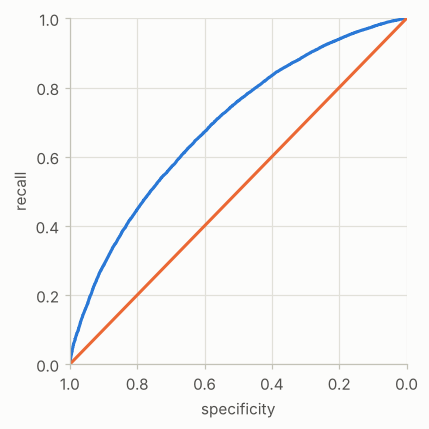

In [20]:
# BOOK CODE (ROC Curve): the ROC curve
# The function `roc_curve` in _Scikit-learn_ calculates all the information that is required for plotting a ROC curve.

fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.plot((1, 0), (0, 1))
ax.set_xlabel('specificity')
ax.set_ylabel('recall')


plt.tight_layout()
plt.show()

The AUC, computed in two ways: as the area under the ROC curve by a sum of rectangles, and with `roc_auc_score`; the figure shades the area.

0.6917107972342917
0.6917108750592037


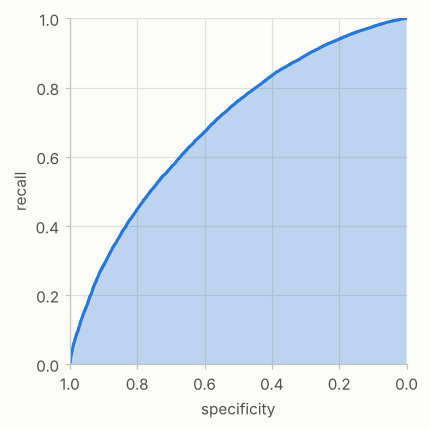

In [21]:
# BOOK CODE (AUC): the area under the ROC curve
# Accuracy can easily be calculated using the _scikit-learn_ function `accuracy_score`.

print(np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity)))
print(roc_auc_score([1 if yi == 'default' else 0 for yi in y], logit_reg.predict_proba(X)[:, 0]))

fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:,0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
# ax.plot((1, 0), (0, 1))
ax.set_xlabel('specificity')
ax.set_ylabel('recall')
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.3)


plt.tight_layout()
plt.show()

**Output analysis.**

* **The confusion matrix** (computed by hand, by scikit-learn and by `dmba`, which agree): of the 22,671 defaults the model finds 14,336 (true positives) and misses 8,335; of the 22,671 loans paid off it classifies 14,523 correctly and calls 8,148 of them defaults (false positives). The accuracy is $(14{,}336 + 14{,}523)/45{,}342 = 0.6365$.
* **Precision, recall and specificity.** Precision is 0.638 (of the loans predicted to default, 63.8% do), recall 0.632 (63.2% of the defaults are found) and specificity 0.641 (64.1% of the loans paid off are recognized). The function `precision_recall_fscore_support` gives the same numbers for both classes: precision 0.638 and 0.635, recall 0.632 and 0.641, F-score 0.635 and 0.638, with 22,671 loans each. The recall of the class `paid off` is the specificity.
* **The ROC curve** lies above the diagonal of random guessing, but not by much; the AUC is 0.6917 both from the sum of rectangles (0.69171080) and from `roc_auc_score` (0.69171088). It means that a randomly chosen loan in default has a higher predicted probability of default than a randomly chosen loan paid off in 69% of the pairs.
* With balanced classes an accuracy of 0.6365 is better than the 0.5 of guessing, but the model is far from perfect. The measures are computed on the data that were used to fit the model, so for new loans they would be a little worse.

---
## 5. Strategies for imbalanced data

*Book section: "Strategies for Imbalanced Data" (undersampling, oversampling and up/down weighting, data generation, cost-based classification, exploring the predictions). The code of the script uses the full set of 119,987 loans, of which 19% are in default.*

### Summary

* The classification of a **rare class** is hard: a model fitted to data with a few positives is rewarded for predicting the common class, and the minority class is rarely predicted. Yet in practice the rare class (fraud, default, a sale) is usually the one of interest. Several strategies change the way the model sees the data.
* **Undersampling:** use fewer of the records of the common class so that the data are more balanced (the file `loan_data.csv.gz` of the previous sections is such a sample, with as many defaults as paid-off loans). It is the simplest strategy, but it throws data away; with enough data it is a good choice.
* **Oversampling and up/down weighting:** instead of removing records, use the rare records more, either by drawing them again (with replacement) or by giving them a larger **weight** in the fit (and the common ones a smaller weight). Weighting does not change the data, but the criterion that is optimized.
* **Data generation:** instead of repeating the rare records, create new, **synthetic** ones. **SMOTE** (synthetic minority oversampling technique) takes a rare record and one of its nearest rare neighbours and creates a new record at a random point of the line segment between them; **ADASYN** is a variant that generates more synthetic records for rare records that are in regions with more common records (harder to learn). The Python package `imbalanced-learn` implements them.
* **Cost-based classification:** the cutoff of 0.5 for the predicted probability is not always right; when a missed positive costs much more than a false alarm, the cutoff should be lowered. The costs of the errors determine a cutoff (the book also describes a way to account for the cost of the different outcomes).
* **Exploring the predictions:** a single number such as the AUC does not show how the models differ. A plot of the **decision boundary** shows which records each model classifies as positive. The script compares a decision tree, a linear discriminant analysis, a logistic regression and a generalized additive model for the loans: the first has a step-like boundary, the second and the third straight lines, and the fourth a smooth curve.
* In the example of the script the logistic regression for the full data (19% defaults) predicts only about 1% defaults; giving the defaults a weight of 5.3 raises that to about 61%; SMOTE and ADASYN give predicted default shares of about 29% and 28%.

### Theory

**Why the minority class is under-predicted.** A classifier that maximizes the likelihood fits the average: a record is predicted *default* only if its estimated probability of default exceeds 0.5. With 19% of defaults and predictors of limited power, very few records reach that probability, so the confusion matrix has almost no predicted defaults. The estimated *probabilities* can still be good (they average about the base rate); it is the cutoff that is wrong for the purpose.

**Weights.** Giving the positive records the weight $w_1$ and the others $w_0$ changes the log-likelihood to $\sum_i w_{y_i}\,[y_i\ln p_i + (1-y_i)\ln(1-p_i)]$. With $w_1/w_0 = (1-\pi)/\pi$, where $\pi$ is the share of positives, the two classes weigh equally, like in a balanced sample; the predicted probabilities then refer to the balanced population, not to the original one, and have to be corrected if the real probabilities are needed.

**SMOTE.** For a minority record $x$ and one of its $k$ nearest minority neighbours $x'$, the synthetic record is $x + u\,(x' - x)$ with $u$ uniform on $(0, 1)$. The synthetic records lie in the convex hull of the minority records near each other; they carry no new information but they smooth the minority region. ADASYN weights the records by the share of majority records among their nearest neighbours and generates more records for those with a high share. Synthetic records have to be generated *after* splitting the data into training and test sets, and only for the training data; otherwise information leaks into the evaluation.

**The cost-based cutoff.** If a false negative costs $c_{FN}$ and a false positive $c_{FP}$, classifying a record with the probability $p$ as positive has the expected cost $(1-p)\,c_{FP}$ and as negative $p\,c_{FN}$; the positive class is chosen if $p > c_{FP}/(c_{FP} + c_{FN})$. With equal costs the cutoff is 0.5.

### Book code

The script first reads the full training set (119,987 loans with 19 columns) and fits the logistic regression with a few more predictors. The heading of the section is *undersampling*, but the code shows the problem that undersampling addresses: the share of defaults among the loans and among the *predicted* defaults. (The script calls `print` inside `print`: the inner call prints the percentage, and the outer call then prints its text followed by `None`.) The last expression of the cell is the ratio of the actual to the predicted share of defaults.

In [22]:
# BOOK CODE (Undersampling): the rare class problem on the full training set
# > The results differ from the R version, however are equivalent to results obtained using the R code. Model based results are of similar magnitude.

full_train_set = pd.read_csv(FULL_TRAIN_SET_CSV)
print(full_train_set.shape)

print('percentage of loans in default: ',
print(      100 * np.mean(full_train_set.outcome == 'default')))

predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'
X = pd.get_dummies(full_train_set[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = full_train_set[outcome]

full_model = LogisticRegression(penalty='l2', C=1e42, solver='liblinear')
full_model.fit(X, y)
print('percentage of loans predicted to default: ',
print(      100 * np.mean(full_model.predict(X) == 'default')))

(np.mean(full_train_set.outcome == 'default') /
 np.mean(full_model.predict(X) == 'default'))

(119987, 19)
18.894546909248504
percentage of loans in default:  None
1.0134431230049923
percentage of loans predicted to default:  None


np.float64(18.64391447368421)

Up/down weighting: each default gets the weight $1/0.189 \approx 5.3$ and each paid-off loan the weight 1.

In [23]:
# BOOK CODE (Oversampling and Up/Down Weighting): the weighted fit
default_wt = 1 / np.mean(full_train_set.outcome == 'default')
wt = [default_wt if outcome == 'default' else 1 for outcome in full_train_set.outcome]

full_model = LogisticRegression(penalty="l2", C=1e42, solver='liblinear')
full_model.fit(X, y, wt)
print('percentage of loans predicted to default (weighting): ',
print(      100 * np.mean(full_model.predict(X) == 'default')))

61.075783209847735
percentage of loans predicted to default (weighting):  None


Data generation with `imbalanced-learn`: SMOTE and ADASYN generate synthetic defaults so that the classes are about equally frequent; the model is then fitted to the resampled data and its predictions on the original data are counted. (`SMOTE` and `ADASYN` draw random numbers and the script gives them no seed, so the percentages can differ a little from run to run; the cells start with a seed, marked `NOT IN THE BOOK`, so that the output of this notebook is reproducible.)

In [24]:
# BOOK CODE (Data Generation): SMOTE
np.random.seed(1)  # NOT IN THE BOOK: SMOTE draws from NumPy's global generator and the script has no seed
# The package _imbalanced-learn_ provides an implementation of the _SMOTE_ and similar algorithms.

X_resampled, y_resampled = SMOTE().fit_resample(X, y)
print('percentage of loans in default (SMOTE resampled): ',
      100 * np.mean(y_resampled == 'default'))

full_model = LogisticRegression(penalty="l2", C=1e42, solver='liblinear')
full_model.fit(X_resampled, y_resampled)
print('percentage of loans predicted to default (SMOTE): ',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans in default (SMOTE resampled):  50.0
percentage of loans predicted to default (SMOTE):  29.245668280730413


In [25]:
# BOOK CODE (Data Generation): ADASYN
np.random.seed(2)  # NOT IN THE BOOK: ADASYN draws from NumPy's global generator and the script has no seed
X_resampled, y_resampled = ADASYN().fit_resample(X, y)
print('percentage of loans in default (ADASYN resampled): ',
      100 * np.mean(y_resampled == 'default'))

full_model = LogisticRegression(penalty="l2", C=1e42, solver='liblinear')
full_model.fit(X_resampled, y_resampled)
print('percentage of loans predicted to default (ADASYN): ',
print(      100 * np.mean(full_model.predict(X) == 'default')))

percentage of loans in default (ADASYN resampled):  48.56040383751355
27.529649045313242
percentage of loans predicted to default (ADASYN):  None


Exploring the predictions. The script fits four models to the 3,000 loans with the borrower score and the payment-to-income ratio: a decision tree (entropy criterion), the linear discriminant analysis, a logistic regression and a generalized additive model with a smooth term for each predictor. The `print` around `gridsearch` shows the fitted GAM object. The `gridsearch` of `pygam` draws a progress bar with the elapsed time; the cell passes `progress=False` (marked `# CHANGED`) so that the saved output does not depend on the speed of the machine.

In [26]:
# BOOK CODE (Exploring the Predictions): four classifiers for the same data
loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)

logit_reg = LogisticRegression(penalty="l2", solver='liblinear')
logit_reg.fit(X, y)


## model
gam = LinearGAM(s(0) + s(1))
print(gam.gridsearch(X.values, [1 if yi == 'default' else 0 for yi in y], progress=False))  # CHANGED: the script has no progress=False

LinearGAM(callbacks=[Deviance(), Diffs()], fit_intercept=True, 
   max_iter=100, scale=None, terms=s(0) + s(1) + intercept, 
   tol=0.0001, verbose=False)


The predicted class over a grid of the two predictors, for the four models: the shaded region is predicted as default.

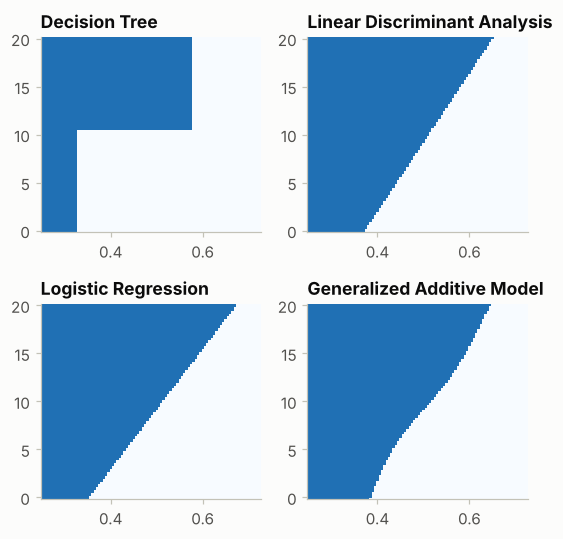

In [27]:
# BOOK CODE (Exploring the Predictions): the regions of the predicted classes
models = {
    'Decision Tree': loan_tree,
    'Linear Discriminant Analysis': loan_lda,
    'Logistic Regression': logit_reg,
    'Generalized Additive Model': gam,
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))

xvalues = np.arange(0.25, 0.73, 0.005)
yvalues = np.arange(-0.1, 20.1, 0.1)
xx, yy = np.meshgrid(xvalues, yvalues)
X = pd.DataFrame({
    'borrower_score': xx.ravel(),
    'payment_inc_ratio': yy.ravel(),
})

boundary = {}

for n, (title, model) in enumerate(models.items()):
    ax = axes[n // 2, n % 2]
    predict = model.predict(X)
    if 'Generalized' in title:
        Z = np.array([1 if z > 0.5 else 0 for z in predict])
    else:

        Z = np.array([1 if z == 'default' else 0 for z in predict])
    Z = Z.reshape(xx.shape)
    boundary[title] = yvalues[np.argmax(Z > 0, axis=0)]
    boundary[title][Z[-1,:] == 0] = yvalues[-1]

    c = ax.pcolormesh(xx, yy, Z, cmap='Blues', vmin=0.1, vmax=1.3, shading='auto')
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()

The boundaries of the four models in one picture.

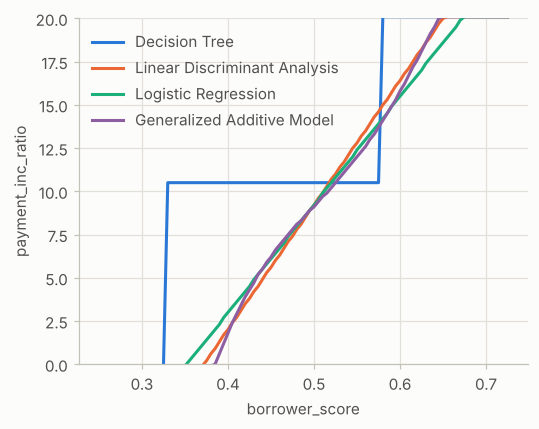

In [28]:
# BOOK CODE (Exploring the Predictions): the decision boundaries
boundary['borrower_score'] = xvalues
boundaries = pd.DataFrame(boundary)

fig, ax = plt.subplots(figsize=(5, 4))
boundaries.plot(x='borrower_score', ax=ax)
ax.set_ylabel('payment_inc_ratio')
ax.set_ylim(0, 20)


plt.tight_layout()
plt.show()

**Output analysis.**

* **The rare class problem.** The full training set has 119,987 loans, of which 18.89% are in default. The logistic regression predicts a default for only 1.01% of the loans: the actual share is 18.6 times the predicted one (the last line, shown by `numpy` 2 as `np.float64(18.64...)`). The lines with `None` come from the `print` inside `print` of the script: the inner `print` shows the number, the outer one the text and `None`.
* **Weighting.** With each default weighted 5.3 times, the model predicts defaults for 61.08% of the loans: now it overshoots by a factor of three, since the fit refers to a population in which the two classes weigh about the same.
* **Data generation.** After SMOTE the resampled data have exactly 50.0% defaults and the model fitted to them predicts 29.2% defaults on the original data; ADASYN creates 48.56% defaults and the model predicts 27.5%. Both are above the actual 18.9% but much closer to it than the weighted fit; the exact values depend on the random numbers (this notebook seeds them).
* **The regions of the four classifiers.** The decision tree has a step-like boundary: it predicts default for all loans with a borrower score below about 0.33, and also for loans with a payment-to-income ratio above about 10.5 and a score below about 0.575. The linear discriminant analysis and the logistic regression have nearly the same straight boundary, and the generalized additive model a slightly curved one close to them. The straight lines run from a borrower score of about 0.35 to 0.40 at a ratio of 0 to about 0.65 to 0.7 at a ratio of 20. The four models therefore agree on the broad pattern; they differ at the edges and in the form of the boundary.

---
## Chapter summary

**Classification predicts a category, usually through a probability.** **Naive Bayes** multiplies the probabilities of the predictor values within each class as if they were independent; **discriminant analysis** finds the linear combination of numeric predictors that best separates the classes; **logistic regression** models the **log-odds** as a linear function of the predictors, is fitted by maximum likelihood (a GLM with the binomial family) and gives coefficients that are read as **odds ratios**. A classifier is evaluated with the **confusion matrix** and the measures derived from it (**precision, recall, specificity**), with the **ROC curve** and the **AUC** over all cutoffs, and with the **lift**; **accuracy** alone is misleading for a **rare class**. For imbalanced data one can undersample, oversample, **weight** the records, **generate synthetic records** (SMOTE, ADASYN) or choose the cutoff by the **costs** of the errors; plotting the **decision boundaries** shows how different classifiers divide the predictor space.

### Key takeaways

1. The naive Bayes model assigns a probability of 0.654 to default for one loan; its probabilities rely on the independence assumption (section 1).
2. The linear discriminant gives a straight decision line in the plane of the borrower score and the payment-to-income ratio (section 2).
3. In logistic regression the coefficients are log-odds: a small-business loan has about 3.4 times the odds of default of a credit-card loan, and a longer employment about 0.70 times; scikit-learn's coefficients refer to the second class (`paid off`) and have the opposite sign to those of a model of default (section 3).
4. A model with an accuracy of 0.6365, a precision of 0.638 and a recall of 0.632 on balanced classes has an AUC of 0.692, a moderate separation (section 4).
5. With 19% defaults the logistic regression predicts only 1% of the loans as defaults; weighting overshoots (61%), SMOTE and ADASYN land at 29% and 28% (section 5).
6. The decision tree has a step-like boundary, whereas linear discriminant analysis, logistic regression and the generalized additive model give nearly the same smooth boundary (section 5).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell, with the changes below. Everything else, in particular what the plots look like, may differ in other versions of the libraries.

* **Paths.** The official script finds its data folder with a helper module; here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing.
* **A change that is needed (`# CHANGED`).** `gam.gridsearch(X.values, ...)` draws a progress bar with the elapsed time; the cell passes `progress=False`, which does not change the fitted model.
* **The deprecation of `penalty`.** The code passes `penalty='l2'` to `LogisticRegression`. scikit-learn 1.8 and later deprecate this argument (it suggests `l1_ratio` and `C` instead) and print a `FutureWarning` for every fit; the code still works. The setup cell silences that one warning so that the output stays readable. With `C=1e42` the penalty is negligible either way.
* **Seeds.** `SMOTE` and `ADASYN` draw from NumPy's global generator and the script has no seed, so the percentages of the output change a little between runs; the two cells start with `np.random.seed(...)  # NOT IN THE BOOK`. The decision tree has `random_state=1` in the script itself.
* **The backend of Matplotlib.** Importing `dmba` prints `no display found. Using non-interactive Agg backend` and selects that backend when no display is found (a server, a background run). Then no figure is shown in a notebook, so the cell after the imports, which is not in the book, runs `%matplotlib inline`.
* **Libraries outside the standard installation.** `imbalanced-learn`, `pygam` and `dmba` have to be installed; the setup cell does it when they are missing, as in Google Colab.
* **Quirks of the script.** `loan_data.outcome.cat.reorder_categories([...])` is not assigned and has no effect; `print('...', print(...))` prints the number first and then the text with `None`; the cell under the heading *undersampling* does not undersample (it shows the rare class problem that undersampling addresses); `f` and `BorderlineSMOTE` are imported and not used. The last expression of the cell with the ratio of the default shares is shown by `numpy` 2 as `np.float64(18.64...)`.
* **The coding of the classes.** scikit-learn orders the classes alphabetically (`default`, `paid off`), and the coefficients of `LogisticRegression` refer to the second one, so they have the opposite sign of those of a model of default, as the script notes.
* **The summaries of `statsmodels` print the date and the time** of the run, so the saved output changes each time the notebook is executed.
* **Plot style.** The setup cell sets the `Matplotlib` style globally, so the figures of the book code also have this notebook's style; its colour cycle has five colours, so that the plot with four lines has four different ones.
* **License.** The code and the data of the official repository are under the GNU General Public License v3. This repository does not redistribute the data: the notebook downloads it at run time, and the `data` folder is ignored by git.

---
## References

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).
* Chawla, N. V., Bowyer, K. W., Hall, L. O. and Kegelmeyer, W. P. (2002). SMOTE: synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research*, 16, 321-357.
* Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of Eugenics*, 7(2), 179-188.
* He, H., Bai, Y., Garcia, E. A. and Li, S. (2008). ADASYN: adaptive synthetic sampling approach for imbalanced learning. *2008 IEEE International Joint Conference on Neural Networks*, 1322-1328.
* The versions of `NumPy`, `pandas`, `SciPy`, `statsmodels`, `scikit-learn`, `imbalanced-learn`, `pygam` and `Matplotlib` are printed by the setup cell.